## 1. Install and import the libraries

If you are running this in a new environment, run this in your terminal first:

```bash
pip install pandas numpy matplotlib seaborn jupyter
```

Then launch Jupyter Notebook and open this file. The libraries are used for data cleaning (`pandas`/`numpy`) and charts (`matplotlib`/`seaborn`).

In [11]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load the dataset

1. Download the **Unemployment in India** dataset from [Kaggle](https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india).
2. Extract the ZIP file.
3. Place `Unemployment in India.csv` in the same folder as this notebook. If your downloaded CSV has a slightly different name, the notebook will try to find a CSV with “unemployment” in its filename.

Do not upload a ZIP file to `read_csv`; extract it first.

In [12]:
# Change this filename if your downloaded CSV uses a different name.
DATA_PATH = Path("Unemployment in India.csv")

if not DATA_PATH.exists():
    candidates = [p for p in Path(".").glob("*.csv") if "unemployment" in p.name.lower()]
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
    elif len(candidates) > 1:
        raise FileNotFoundError(
            "More than one unemployment CSV was found: "
            + ", ".join(p.name for p in candidates)
            + ". Set DATA_PATH to the exact file you want to analyse."
        )
    else:
        raise FileNotFoundError(
            "CSV not found. Download and extract the Kaggle dataset, place its CSV beside this notebook, "
            "then set DATA_PATH to its filename."
        )

raw_df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Raw dataset shape: {raw_df.shape[0]} rows × {raw_df.shape[1]} columns")
display(raw_df.head())

Loaded: Unemployment in India.csv
Raw dataset shape: 768 rows × 7 columns


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 3. Inspect the original data

Check the shape, column types, summary statistics, and missing values **before** cleaning. This helps explain what needs to be fixed instead of silently changing the source data.

In [13]:
print("Dataset shape:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())
print("\nData types:")
print(raw_df.dtypes)
print("\nMissing values by column (raw data):")
display(raw_df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nDescriptive statistics (raw data):")
display(raw_df.describe(include="all").T)

Dataset shape: (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Data types:
Region                                       object
 Date                                        object
 Frequency                                   object
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                         object
dtype: object

Missing values by column (raw data):


,missing_count
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28



Descriptive statistics (raw data):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,740,28,Andhra Pradesh,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,740,14,31-10-2019,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,740,2,Monthly,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),740.0,NaN,NaN,NaN,11.787946,10.721298,0.0,4.6575,8.35,15.8875,76.74
Estimated Employed,740.0,NaN,NaN,NaN,7204460.025676,8087988.429458,49420.0,1190404.5,4744178.5,11275489.5,45777509.0
Estimated Labour Participation Rate (%),740.0,NaN,NaN,NaN,42.630122,8.111094,13.33,38.0625,41.16,45.505,72.57
Area,740,2,Urban,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Standardise columns and clean the data

The dataset is distributed in slightly different CSV variants. This cell identifies the state/region, date, unemployment rate, employed estimate, and labour-participation columns using their names. It also handles whitespace, converts dates/numbers, removes empty index columns, and drops rows that cannot be used for the required analysis.

For datasets containing both `States` and `Region`, the state names are used as the analysis region; `Region` can sometimes mean a broader zone such as North or South.

In [14]:
# Remove stray spaces from column names and discard CSV index columns such as "Unnamed: 0".
clean_source = raw_df.copy()
clean_source.columns = [str(col).strip() for col in clean_source.columns]
clean_source = clean_source.loc[:, ~clean_source.columns.str.match(r"(?i)^unnamed")] 

# Make column-name matching tolerant of spaces, punctuation, and capitalisation.
def compact_name(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

column_lookup = {compact_name(col): col for col in clean_source.columns}

def exact_column(candidates):
    for candidate in candidates:
        if candidate in column_lookup:
            return column_lookup[candidate]
    return None

def contains_column(required_words, exclude_words=()):
    for compact, original in column_lookup.items():
        if all(word in compact for word in required_words) and not any(word in compact for word in exclude_words):
            return original
    return None

# Prefer State/States if the file contains both a state column and a zone/region column.
region_col = exact_column(["state", "states", "unionterritory", "territory", "region"])
date_col = exact_column(["date", "observationdate", "monthdate"])
unemployment_col = exact_column([
    "estimatedunemploymentrate", "estimatedunemploymentratepercent", "unemploymentrate", "unemploymentratepercent"
]) or contains_column(["unemployment", "rate"])
employed_col = exact_column(["estimatedemployed", "employed", "estimatedemployment"]) or contains_column(["employed"], ["unemployment"])
participation_col = exact_column([
    "estimatedlabourparticipationrate", "estimatedlaborparticipationrate",
    "labourparticipationrate", "laborparticipationrate"
]) or contains_column(["participation", "rate"])
area_col = exact_column(["area", "areatype"])
frequency_col = exact_column(["frequency"])

selected_columns = {
    "region": region_col,
    "date": date_col,
    "unemployment_rate": unemployment_col,
    "estimated_employed": employed_col,
    "labour_participation_rate": participation_col,
}
missing_required = [key for key, value in selected_columns.items() if value is None]
if missing_required:
    raise ValueError(
        "Could not identify required column(s): " + ", ".join(missing_required) +
        ". Check the CSV headers printed above and update the column-mapping cell."
    )

rename_map = {source: standard for standard, source in selected_columns.items()}
if area_col:
    rename_map[area_col] = "area"
if frequency_col:
    rename_map[frequency_col] = "frequency"
df = clean_source.rename(columns=rename_map).copy()

# Trim strings and parse the date column. dayfirst=True suits common DD-MM-YYYY source dates.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()
try:
    df["date"] = pd.to_datetime(df["date"], errors="coerce", dayfirst=True, format="mixed")
except TypeError:  # Compatibility with older pandas versions
    df["date"] = pd.to_datetime(df["date"], errors="coerce", dayfirst=True)

# Convert metric columns to numeric, even when values include commas or a percent sign.
for col in ["unemployment_rate", "estimated_employed", "labour_participation_rate"]:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False).str.replace("%", "", regex=False).str.strip(),
        errors="coerce"
    )

rows_before = len(df)
df = df.dropna(subset=["region", "date", "unemployment_rate"]).copy()
df["region"] = df["region"].astype(str).str.strip()
df = df[df["region"].ne("")]
df = df.drop_duplicates().copy()
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()

print(f"Rows before required-field cleaning: {rows_before}")
print(f"Rows after required-field cleaning and de-duplication: {len(df)}")
print(f"Rows removed: {rows_before - len(df)}")
print("Clean dataset shape:", df.shape)
print("\nCleaned data types:")
print(df.dtypes)
print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("missing_count"))
display(df.head())

Rows before required-field cleaning: 768
Rows after required-field cleaning and de-duplication: 740
Rows removed: 28
Clean dataset shape: (740, 8)

Cleaned data types:
region                               object
date                         datetime64[ns]
frequency                    string[python]
unemployment_rate                   Float64
estimated_employed                  Float64
labour_participation_rate           Float64
area                         string[python]
month                        datetime64[ns]
dtype: object

Missing values after cleaning:


,missing_count
region,0
date,0
frequency,0
unemployment_rate,0
estimated_employed,0
labour_participation_rate,0
area,0
month,0


,region,date,frequency,unemployment_rate,estimated_employed,labour_participation_rate,area,month
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019-05-01
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,2019-06-01
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.5,Rural,2019-07-01
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,2019-08-01
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,2019-09-01


## 5. Exploratory data analysis (EDA)

Start with overall coverage, the number of regions and dates, and the region-wise mean unemployment rate. The mean is an unweighted average of available observations; it should be described as a dataset-level average, not an official population-weighted national estimate.

In [15]:
print(f"Coverage: {df['date'].min():%B %Y} to {df['date'].max():%B %Y}")
print("Number of unique regions/states:", df["region"].nunique())
print("Number of monthly observations:", df["month"].nunique())
print("\nOverall metric summary:")
display(df[["unemployment_rate", "estimated_employed", "labour_participation_rate"]].describe().T)

region_summary = (
    df.groupby("region", as_index=False)
      .agg(
          average_unemployment_rate=("unemployment_rate", "mean"),
          average_employed=("estimated_employed", "mean"),
          average_labour_participation=("labour_participation_rate", "mean"),
          observations=("unemployment_rate", "count"),
      )
      .sort_values("average_unemployment_rate", ascending=False)
)
display(region_summary.head(10).round(2))

Coverage: May 2019 to June 2020
Number of unique regions/states: 28
Number of monthly observations: 14

Overall metric summary:


,count,mean,std,min,25%,50%,75%,max
unemployment_rate,740.0,11.787946,10.721298,0.0,4.6575,8.35,15.8875,76.74
estimated_employed,740.0,7204460.025676,8087988.429458,49420.0,1190404.5,4744178.5,11275489.5,45777509.0
labour_participation_rate,740.0,42.630122,8.111094,13.33,38.0625,41.16,45.505,72.57


,region,average_unemployment_rate,average_employed,average_labour_participation,observations
24,Tripura,28.35,717002.64,61.82,28
8,Haryana,26.28,3557072.46,42.74,28
11,Jharkhand,20.58,4469240.43,41.67,28
2,Bihar,18.92,12366189.14,38.15,28
9,Himachal Pradesh,18.54,1059823.71,44.22,28
5,Delhi,16.5,2627512.86,38.93,28
10,Jammu & Kashmir,16.19,1799931.67,41.03,21
3,Chandigarh,15.99,316831.25,39.34,12
20,Rajasthan,14.06,10041064.75,39.97,28
25,Uttar Pradesh,12.55,28094832.18,39.43,28


### Chart 1 — Month-wise unemployment trend

This line chart shows how the mean unemployment rate across available observations changes month by month. Each point is the average for that month across the rows in the dataset; where Rural and Urban rows exist, both contribute to that average.

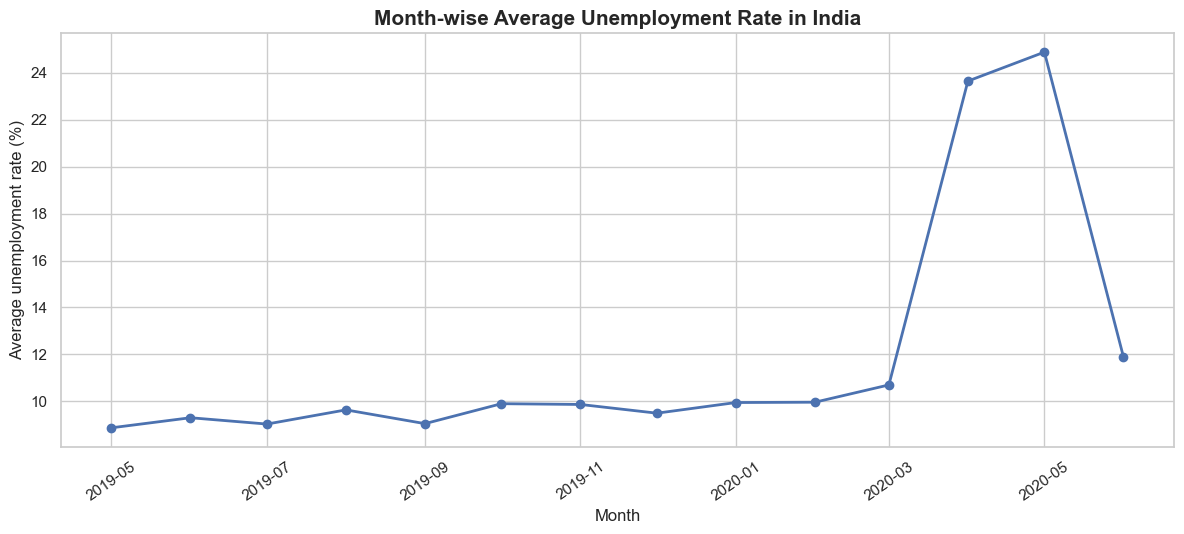

Observation: The highest monthly mean in this dataset is 24.88% (May 2020); the lowest is 8.87% (May 2019). Verify the pattern visually and discuss possible historical context.


In [16]:
monthly_mean = (
    df.groupby("month", as_index=False)["unemployment_rate"]
      .mean()
      .sort_values("month")
)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(monthly_mean["month"], monthly_mean["unemployment_rate"], marker="o", linewidth=2)
ax.set_title("Month-wise Average Unemployment Rate in India", fontsize=15, weight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Average unemployment rate (%)")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_monthly_unemployment_trend.png", dpi=220, bbox_inches="tight")
plt.show()

if not monthly_mean.empty:
    peak_row = monthly_mean.loc[monthly_mean["unemployment_rate"].idxmax()]
    low_row = monthly_mean.loc[monthly_mean["unemployment_rate"].idxmin()]
    print(
        f"Observation: The highest monthly mean in this dataset is {peak_row['unemployment_rate']:.2f}% "
        f"({peak_row['month']:%B %Y}); the lowest is {low_row['unemployment_rate']:.2f}% "
        f"({low_row['month']:%B %Y}). Verify the pattern visually and discuss possible historical context."
    )

### Chart 2 — Time-series trends for three regions

The code selects the three regions with the broadest monthly coverage so that their trends can be compared fairly. Each region is aggregated by month in case it has multiple records per month (for example, Rural and Urban observations).

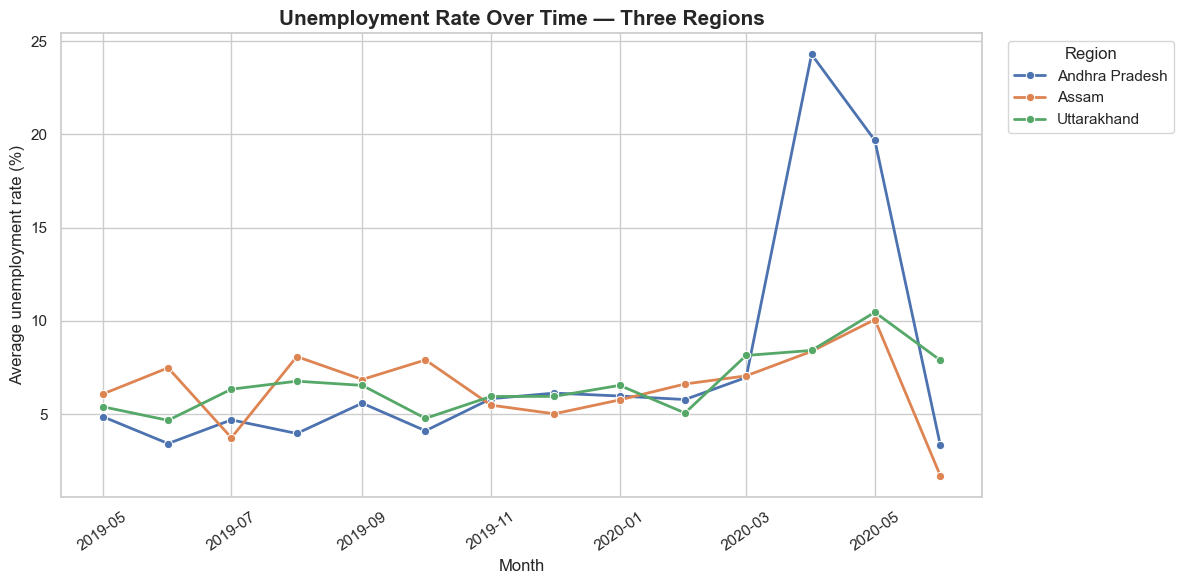

Regions shown: Andhra Pradesh, Assam, Uttarakhand
Observation: Compare the timing and size of peaks across the three lines. Note whether the regions move together or show different patterns.


In [17]:
monthly_coverage = df.groupby("region")["month"].nunique().sort_values(ascending=False)
selected_regions = monthly_coverage.head(3).index.tolist()
regional_monthly = (
    df[df["region"].isin(selected_regions)]
      .groupby(["month", "region"], as_index=False)["unemployment_rate"]
      .mean()
      .sort_values("month")
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=regional_monthly,
    x="month", y="unemployment_rate", hue="region", marker="o", linewidth=2, ax=ax
)
ax.set_title("Unemployment Rate Over Time — Three Regions", fontsize=15, weight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Average unemployment rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_three_region_time_series.png", dpi=220, bbox_inches="tight")
plt.show()

print("Regions shown:", ", ".join(selected_regions))
print("Observation: Compare the timing and size of peaks across the three lines. Note whether the regions move together or show different patterns.")

### Chart 3 — Top 10 regions by average unemployment rate

This ranking compares each region's mean unemployment rate over the full period available in the CSV. The observation window may be different for different regions, so use the coverage counts in `region_summary` when interpreting close comparisons.

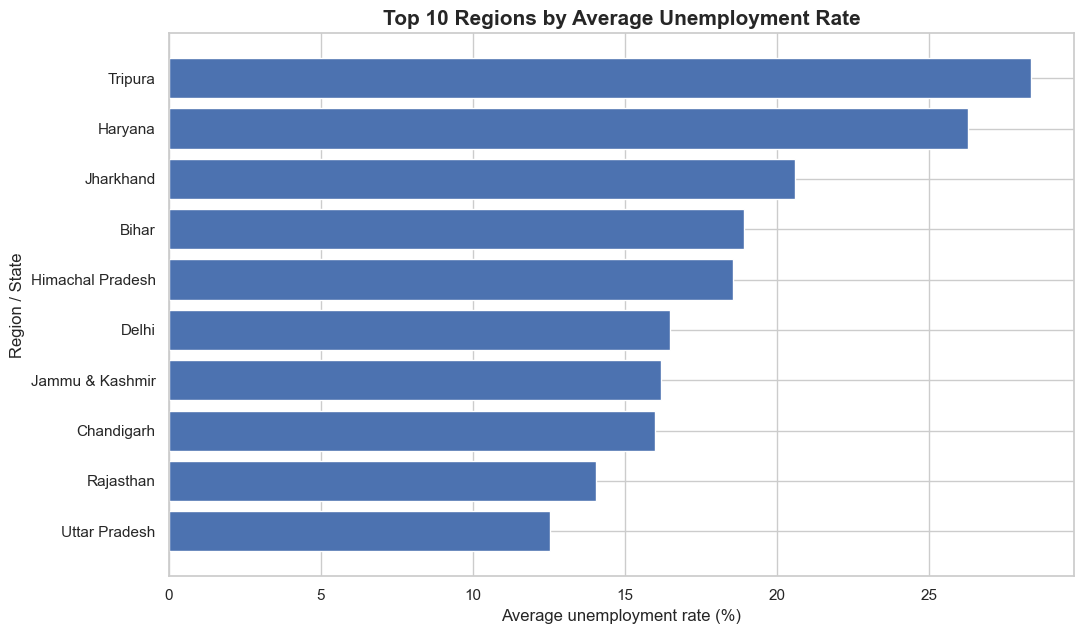

Observation: Tripura has the highest average unemployment rate among the regions shown (28.35%). Check the full table before describing the lowest region or regional differences.


In [18]:
top10_regions = region_summary.nlargest(10, "average_unemployment_rate").sort_values("average_unemployment_rate")

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(top10_regions["region"], top10_regions["average_unemployment_rate"])
ax.set_title("Top 10 Regions by Average Unemployment Rate", fontsize=15, weight="bold")
ax.set_xlabel("Average unemployment rate (%)")
ax.set_ylabel("Region / State")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_top_10_regions.png", dpi=220, bbox_inches="tight")
plt.show()

if not top10_regions.empty:
    highest = top10_regions.iloc[-1]
    print(
        f"Observation: {highest['region']} has the highest average unemployment rate among the regions shown "
        f"({highest['average_unemployment_rate']:.2f}%). Check the full table before describing the lowest region or regional differences."
    )

### Chart 4 — Correlation heatmap

The heatmap shows pairwise Pearson correlations among the unemployment rate, estimated employed count, and labour-force participation rate. A correlation close to +1 means the two variables tend to rise together in these observations; close to −1 means they tend to move in opposite directions. **Correlation does not prove that one variable causes another.**

,Unemployment rate (%),Estimated employed,Labour participation rate (%)
Unemployment rate (%),1.000,-0.223,0.003
Estimated employed,-0.223,1.000,0.011
Labour participation rate (%),0.003,0.011,1.000


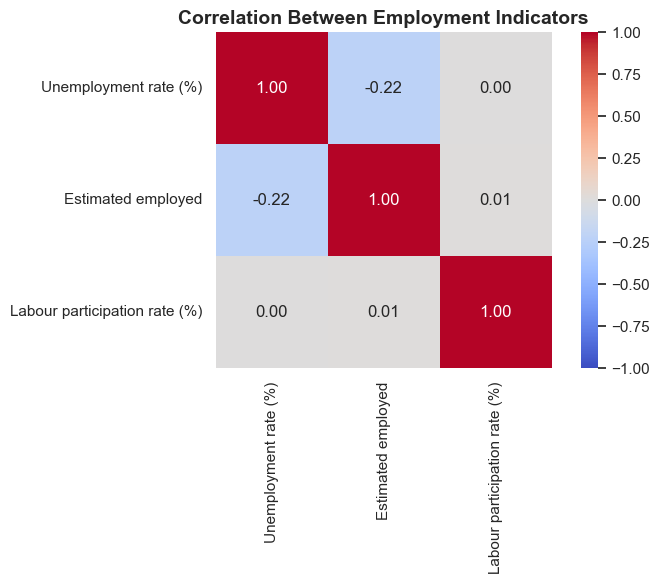

Observation: The strongest pairwise relationship shown is negative (r = -0.22) between Unemployment rate (%) and Estimated employed.


In [19]:
metric_columns = ["unemployment_rate", "estimated_employed", "labour_participation_rate"]
metric_labels = {
    "unemployment_rate": "Unemployment rate (%)",
    "estimated_employed": "Estimated employed",
    "labour_participation_rate": "Labour participation rate (%)",
}
correlation_matrix = df[metric_columns].corr(numeric_only=True).rename(index=metric_labels, columns=metric_labels)

display(correlation_matrix.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation Between Employment Indicators", fontsize=14, weight="bold")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_correlation_heatmap.png", dpi=220, bbox_inches="tight")
plt.show()

# Find the strongest absolute off-diagonal correlation that exists in the matrix.
upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)).stack().dropna()
if len(upper):
    strongest_pair = upper.abs().idxmax()
    value = upper.loc[strongest_pair]
    direction = "positive" if value > 0 else "negative"
    print(f"Observation: The strongest pairwise relationship shown is {direction} (r = {value:.2f}) between {strongest_pair[0]} and {strongest_pair[1]}.")
else:
    print("Observation: There were not enough non-missing values to compute a complete correlation comparison.")

### Chart 5 — Pre-COVID vs COVID-period comparison

For a reproducible comparison, this notebook defines **pre-COVID** as dates before **1 March 2020** and **COVID period** as 1 March 2020 onward. March 2020 marks the period when the nationwide lockdown began; the exact cutoff is a simplifying analytical choice. Because this dataset typically ends in 2020, it does **not** establish long-term post-pandemic outcomes.

,period,mean_unemployment_rate,observations,mean_employed,mean_labour_participation
1,Pre-COVID (before Mar 2020),9.51,536,7466027.87,43.89
0,COVID period (Mar 2020 onward),17.77,204,6517203.34,39.33


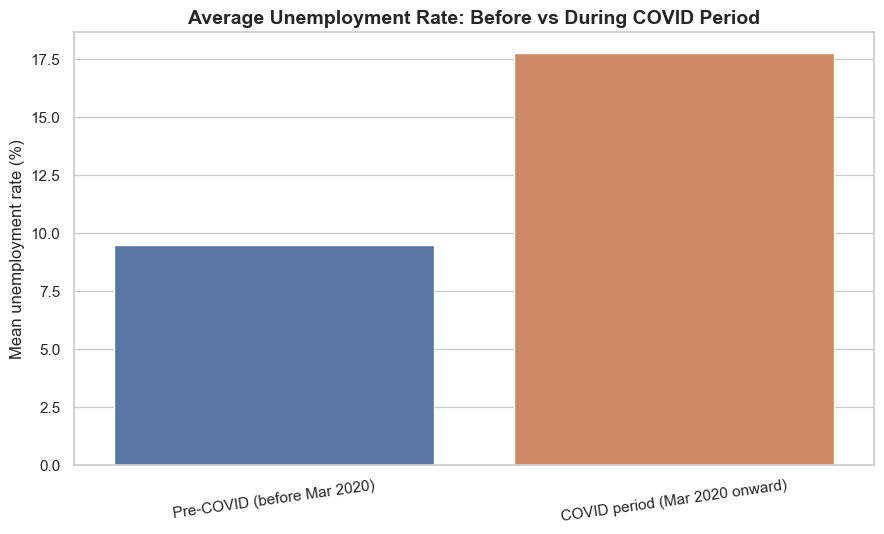

Observation: The mean rate changed from 9.51% before March 2020 to 17.77% from March 2020 onward.
Absolute difference: +8.26 percentage points. Relative change: +86.9% (relative to the pre-COVID mean).
Interpret this as a descriptive comparison in this dataset, not proof that COVID alone caused every difference.


In [20]:
COVID_CUTOFF = pd.Timestamp("2020-03-01")
df["period"] = np.where(df["date"] < COVID_CUTOFF, "Pre-COVID (before Mar 2020)", "COVID period (Mar 2020 onward)")

period_summary = (
    df.groupby("period", as_index=False)
      .agg(
          mean_unemployment_rate=("unemployment_rate", "mean"),
          observations=("unemployment_rate", "count"),
          mean_employed=("estimated_employed", "mean"),
          mean_labour_participation=("labour_participation_rate", "mean"),
      )
)
period_order = ["Pre-COVID (before Mar 2020)", "COVID period (Mar 2020 onward)"]
period_summary["period"] = pd.Categorical(period_summary["period"], categories=period_order, ordered=True)
period_summary = period_summary.sort_values("period")
display(period_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=period_summary, x="period", y="mean_unemployment_rate", hue="period", legend=False, ax=ax)
ax.set_title("Average Unemployment Rate: Before vs During COVID Period", fontsize=14, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Mean unemployment rate (%)")
ax.tick_params(axis="x", rotation=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_pre_covid_vs_covid_period.png", dpi=220, bbox_inches="tight")
plt.show()

means = period_summary.set_index("period")["mean_unemployment_rate"]
pre_label = "Pre-COVID (before Mar 2020)"
covid_label = "COVID period (Mar 2020 onward)"
if pre_label in means.index and covid_label in means.index and pd.notna(means.get(pre_label)) and pd.notna(means.get(covid_label)):
    difference = means[covid_label] - means[pre_label]
    relative = (difference / means[pre_label] * 100) if means[pre_label] != 0 else np.nan
    print(f"Observation: The mean rate changed from {means[pre_label]:.2f}% before March 2020 to {means[covid_label]:.2f}% from March 2020 onward.")
    print(f"Absolute difference: {difference:+.2f} percentage points. Relative change: {relative:+.1f}% (relative to the pre-COVID mean).")
    print("Interpret this as a descriptive comparison in this dataset, not proof that COVID alone caused every difference.")
else:
    print("One of the periods has no usable observations. Check the dataset date coverage or adjust COVID_CUTOFF.")

## 6. Final Findings

- **Overall unemployment trend:** The average unemployment rate across the available observations was approximately **11.79%**. The highest monthly average was **24.88% in May 2020**, while the lowest was **8.87% in May 2019**. The monthly trend shows a sharp rise during April and May 2020 compared with the relatively stable rates observed throughout much of 2019.

- **Regional comparison:** The time-series analysis of Andhra Pradesh, Assam, and Uttarakhand shows that unemployment trends differed across regions. Andhra Pradesh experienced a particularly sharp increase during April 2020, reaching approximately 24–25%, before falling considerably in June. Assam and Uttarakhand also showed increases around April and May 2020, although their changes were less extreme.

- **Regions with the highest average unemployment:** Tripura recorded the highest average unemployment rate at **28.35%**, followed by Haryana at **26.28%** and Jharkhand at **20.58%**. Bihar and Himachal Pradesh followed, with average rates of 18.92% and 18.54%, respectively. These results highlight substantial differences in average unemployment across the regions represented in the dataset.

- **Correlation analysis:** The correlation between unemployment rate and estimated employment was approximately **−0.22**, indicating a weak negative relationship in the available observations. The correlation between unemployment rate and labour-force participation rate was approximately **0.003**, indicating virtually no linear relationship. Estimated employment and labour-force participation had a correlation of approximately **0.01**. These relationships describe the observed data and do not establish causation.

- **Pre-COVID versus COVID-period comparison:** The mean unemployment rate increased from **9.51% before March 2020 to 17.77% from March 2020 onward**. This represents an increase of **8.26 percentage points**, or approximately **86.9% relative to the pre-COVID average**. The comparison indicates a substantial rise in unemployment during the COVID-period observations available in this dataset, although it does not prove that COVID-19 alone caused the increase.

- **Data quality and limitations:** The original dataset contained **768 rows**, of which 28 were removed during cleaning, leaving **740 observations** with no missing values in the required analysis columns. The dataset covers May 2019 to June 2020 and contains observations from 28 unique regions or states. The analysis uses averages across the available observations, including rural and urban records where present. Therefore, the results should be interpreted as descriptive findings from the available dataset rather than as population-weighted estimates of India's national unemployment rate. The limited time period also prevents conclusions about long-term post-pandemic recovery.

### Conclusion

The exploratory data analysis reveals significant regional differences in unemployment and a pronounced increase in the average unemployment rate during April and May 2020. The pre-COVID versus COVID-period comparison further demonstrates the scale of this change in the available observations. These findings illustrate how Python libraries such as pandas, Matplotlib, and Seaborn can be used to clean real-world data, identify trends, explore relationships between variables, and communicate insights through visualizations.